# CS00 - Newton's method: the engine inside every AC load flow

**Problem type:** numerical - solving a non-linear equation $f(x)=0$.
**Source:** Exercise 5, Assignment 1 (Power System Modeling, Simulation and Control).

## 1. Why start here?
An AC load flow is a system of non-linear equations. PyPSA, PowerFactory, PSS/E and MATPOWER
all solve it with Newton's method. Understanding the scalar case explains everything we will
see later: the role of the starting point ("flat start"), why the Jacobian matters, why
convergence is usually reached in 3 to 5 iterations, and why a load flow can fail.

## 2. Exercise
Perform 5 iterations of Newton's method on $f(x) = 10x^2 - 2x^3 = 0$.
1. Give the derivative $f'(x)$.
2. Tabulate $x$, $\Delta x$, $f(x)$, $f'(x)$ at each iteration, (a) from $x_0 = 1$,
   (b) from $x_0 = 4$.
3. Sketch $f(x)$ and explain where each run goes.
4. *(Expert)* Explain the different speeds of convergence and find a starting point for
   which the method fails.

## 3. Theory
Newton linearises $f$ around the current guess and jumps to the zero of the tangent:
$$x_{k+1} = x_k + \Delta x_k, \qquad \Delta x_k = -\frac{f(x_k)}{f'(x_k)}.$$
Here $f(x) = 2x^2(5 - x)$, so the roots are $x = 0$ (a **double** root) and $x = 5$
(a **simple** root), and
$$f'(x) = 20x - 6x^2 = 2x(10 - 3x).$$
$f'$ vanishes at $x = 0$ and $x = 10/3$: the tangent is horizontal there, and Newton
cannot be applied.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pscs").exists())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pscs
from pscs.newton import newton_scalar
from pscs.plotting import SERIES, INK2, MUTED, save

DATA, FIG, TAB = pscs.setup()


def f(x):
    return 10 * x**2 - 2 * x**3


def df(x):
    return 20 * x - 6 * x**2

## 4. Solution (a): start at $x_0 = 1$

In [2]:
run_a = newton_scalar(f, df, x0=1.0, n_iter=5)
run_a.to_csv(TAB / "cs00_newton_x0_1.csv")
run_a.round(6)

,x_k,f(x_k),f'(x_k),dx,x_k+1
k,,,,,
0,1.0000,8.0000,14.0000,-0.5714,0.4286
1,0.4286,1.6793,7.4694,-0.2248,0.2037
2,0.2037,0.3982,3.8259,-0.1041,0.0997
3,0.0997,0.0973,1.9337,-0.0503,0.0493
4,0.0493,0.0241,0.9718,-0.0248,0.0245


## 5. Solution (b): start at $x_0 = 4$

In [3]:
run_b = newton_scalar(f, df, x0=4.0, n_iter=5)
run_b.to_csv(TAB / "cs00_newton_x0_4.csv")
run_b.round(6)

,x_k,f(x_k),f'(x_k),dx,x_k+1
k,,,,,
0,4.0000,32.0000,-16.0000,2.0000,6.0000
1,6.0000,-72.0000,-96.0000,-0.7500,5.2500
2,5.2500,-13.7812,-60.3750,-0.2283,5.0217
3,5.0217,-1.0964,-50.8724,-0.0216,5.0002
4,5.0002,-0.0093,-50.0075,-0.0002,5.0000


## 6. Convergence speed: linear versus quadratic
Error $e_k = |x_k - x^*|$. For a **simple** root Newton converges **quadratically**
($e_{k+1} \approx C e_k^2$: the number of correct digits doubles at each step). For a
**double** root the convergence degrades to **linear** with ratio 1/2. Indeed the Newton
update simplifies to
$$x_{k+1} = x_k - \frac{x_k(10-2x_k)}{20-6x_k} = x_k\,\frac{10-4x_k}{20-6x_k}
\;\xrightarrow{x_k\to 0}\; \frac{x_k}{2}.$$

In [4]:
def errors(run, root):
    x = np.r_[run["x_k"].values, run["x_k+1"].values[-1]]
    e = np.abs(x - root)
    return pd.DataFrame({"e_k": e[:-1], "e_k+1": e[1:],
                         "e_k+1 / e_k": e[1:] / e[:-1],
                         "e_k+1 / e_k^2": e[1:] / e[:-1] ** 2})

conv = pd.concat({"x0 = 1 (root 0, double)": errors(run_a, 0.0),
                  "x0 = 4 (root 5, simple)": errors(run_b, 5.0)}, axis=1)
conv.round(5)

x0 = 1 (root 0, double)                                   x0 = 4 (root 5, simple)                                  
                      e_k   e_k+1 e_k+1 / e_k e_k+1 / e_k^2                     e_k   e_k+1 e_k+1 / e_k e_k+1 / e_k^2
0                  1.0000  0.4286      0.4286        0.4286                  1.0000  1.0000  1.0000e+00        1.0000
1                  0.4286  0.2037      0.4754        1.1093                  1.0000  0.2500  2.5000e-01        0.2500
2                  0.2037  0.0997      0.4891        2.4008                  0.2500  0.0217  8.6960e-02        0.3478
3                  0.0997  0.0493      0.4949        4.9654                  0.0217  0.0002  8.5800e-03        0.3948
4                  0.0493  0.0245      0.4975       10.0872                  0.0002  0.0000  7.0000e-05        0.4000

## 7. Where does Newton go? Basins of attraction and failure
We run 30 iterations from many starting points and record the root reached.

In [5]:
starts = np.linspace(-2, 8, 2001)
final = []
for x0 in starts:
    x = x0
    for _ in range(30):
        d = df(x)
        if abs(d) < 1e-12:
            x = np.nan
            break
        x -= f(x) / d
        if abs(x) > 1e6:
            x = np.nan
            break
    final.append(x)
final = np.array(final)
basin = pd.Series(np.where(np.abs(final) < 1e-3, "0", np.where(np.abs(final - 5) < 1e-3, "5", "fail")),
                  index=starts)
print("Share of starting points converging to x = 0:", f"{(basin == '0').mean():.0%}",
      "| to x = 5:", f"{(basin == '5').mean():.0%}")
print("f'(10/3) =", df(10 / 3), " -> Newton cannot start at x0 = 10/3 (horizontal tangent)")
print("x0 = 3.3 gives the first jump", 3.3 - f(3.3) / df(3.3))

Share of starting points converging to x = 0: 53% | to x = 5: 47%
f'(10/3) = 0.0  -> Newton cannot start at x0 = 10/3 (horizontal tangent)
x0 = 3.3 gives the first jump -52.79999999999908


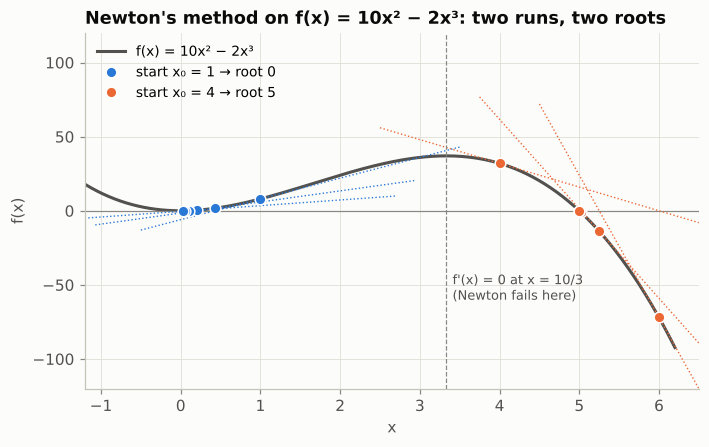

In [6]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
x = np.linspace(-1.2, 6.2, 400)
ax.plot(x, f(x), color=INK2, lw=2, label="f(x) = 10x² − 2x³")
ax.axhline(0, color=MUTED, lw=0.8)
for run, col, lab in [(run_a, SERIES[0], "start x₀ = 1 → root 0"), (run_b, SERIES[1], "start x₀ = 4 → root 5")]:
    xs = np.r_[run["x_k"].values, run["x_k+1"].values[-1]]
    ax.plot(xs, f(xs), "o", color=col, ms=7, label=lab, zorder=3, markeredgecolor="white")
    for xk in run["x_k"].values[:3]:                     # first tangents
        t = np.linspace(xk - 1.5, xk + 2.5, 2)
        ax.plot(t, f(xk) + df(xk) * (t - xk), color=col, lw=0.9, ls=":")
ax.axvline(10 / 3, color=MUTED, lw=0.8, ls="--")
ax.annotate("f'(x) = 0 at x = 10/3\n(Newton fails here)", (10 / 3, -60), xytext=(4, 0),
            textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_ylim(-120, 120); ax.set_xlim(-1.2, 6.5)
ax.set_xlabel("x"); ax.set_ylabel("f(x)")
ax.set_title("Newton's method on f(x) = 10x² − 2x³: two runs, two roots")
ax.legend(loc="upper left")
save(fig, FIG / "cs00_newton_function.png")
fig

## 8. Interpretation (what to say in front of a jury)
- **(a) $x_0 = 1$** converges towards the **double root 0**, but slowly: the error is only
  halved at each iteration (ratio 0.5). After 5 iterations $x \approx 0.025$, still far from
  machine precision.
- **(b) $x_0 = 4$** first overshoots to $x = 6$ (the tangent at 4 has a negative slope),
  then converges to the **simple root 5** quadratically: the ratio $e_{k+1}/e_k^2$ settles
  near a constant (about 0.4), and 5 iterations give 8 exact digits ($x_5 = 5.00000001$).
- **Failure:** at $x_0 = 10/3$ the derivative is zero; close to it, the first step is
  huge (from 3.3 to about -53). The method only converges reliably from a good start.
  About half of the starting points between -2 and 8 end at 0 and half at 5: the root you
  get depends on where you start.

**Link with the load flow.** The vector version replaces $f'(x)$ by the Jacobian matrix
$J$ and solves $J\,\Delta x = -f(x)$. A *flat start* ($|V| = 1$, $\theta = 0$) is a good
guess because real networks operate near nominal voltage. Several solutions can exist
(a normal high-voltage one and an unstable low-voltage one, like the two roots here), and a
singular Jacobian (like $f' = 0$) signals the voltage-collapse point we meet in CS05.

In [7]:
pscs.save_summary("cs00", {
    "x_after_5_from_1": run_a["x_k+1"].iloc[-1],
    "x_after_5_from_4": run_b["x_k+1"].iloc[-1],
    "linear_ratio": conv[("x0 = 1 (root 0, double)", "e_k+1 / e_k")].iloc[-1],
})